In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
from google.cloud import bigquery

PROJECT_ID = "radar-economia-br"
client = bigquery.Client(project=PROJECT_ID, location="US")

df = client.query(f"""
    SELECT * FROM `{PROJECT_ID}.economia_br.vw_base_mensal` ORDER BY mes
""").to_dataframe()
df["mes"] = pd.to_datetime(df["mes"])
df = df.set_index("mes")

Path("../imagens").mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})
df.tail()

/Users/vidigal/Documents/radar-economia-br/.venv/lib/python3.14/site-packages/google/cloud/bigquery/table.py:2122: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,ipca_mensal,ipca_12m,selic_media,dolar_medio,dolar_fim_mes,desemprego,ibc_br,dolar_var_pct,ibc_br_var_12m,juro_real
mes,,,,,,,,,,
2026-05-01 00:00:00+00:00,0.58,4.724907,14.500000,4.983700,5.0569,5.6,109.79468,-0.98,1.12,9.33
2026-06-01 00:00:00+00:00,0.16,4.641328,14.391667,5.127571,5.1766,5.4,110.18456,2.89,2.59,9.32
2026-07-01 00:00:00+00:00,0.07,4.443025,14.250000,5.113948,5.0773,5.3,114.48992,-0.27,1.14,9.39
2026-08-01 00:00:00+00:00,-0.32,4.223453,14.040323,5.153162,5.1816,5.3,111.71919,0.77,1.21,9.42
2026-09-01 00:00:00+00:00,0.82,4.576120,13.883333,5.144724,5.1809,NaN,NaN,-0.16,NaN,8.90


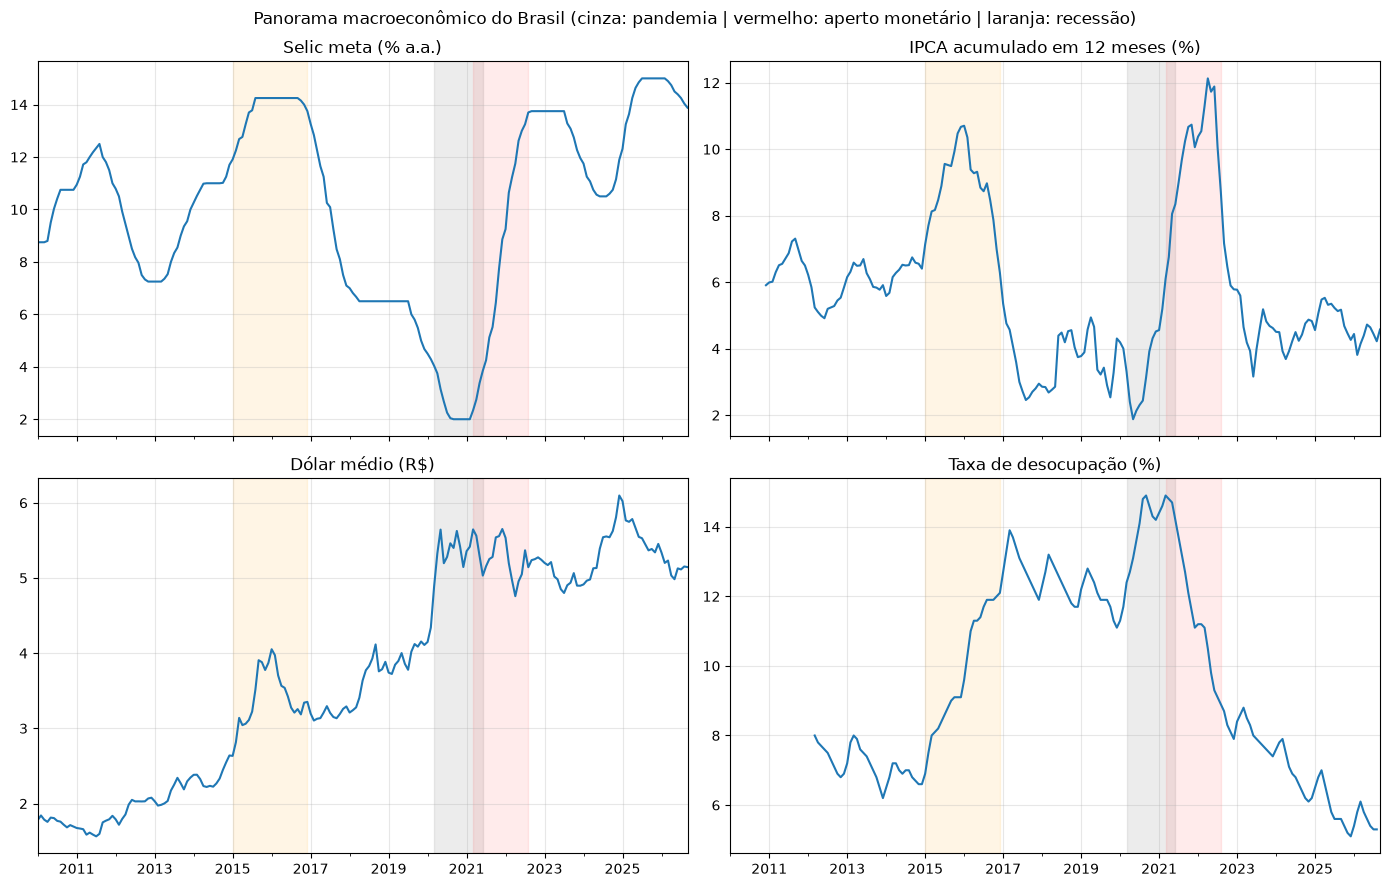

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

df["selic_media"].plot(ax=axes[0, 0], title="Selic meta (% a.a.)")
df["ipca_12m"].plot(ax=axes[0, 1], title="IPCA acumulado em 12 meses (%)")
df["dolar_medio"].plot(ax=axes[1, 0], title="Dólar médio (R$)")
df["desemprego"].plot(ax=axes[1, 1], title="Taxa de desocupação (%)")

for ax in axes.flat:
    ax.axvspan("2020-03-01", "2021-06-30", color="gray", alpha=0.15)    # pandemia
    ax.axvspan("2021-03-01", "2022-08-31", color="red", alpha=0.08)     # ciclo de alta da Selic
    ax.axvspan("2015-01-01", "2016-12-31", color="orange", alpha=0.10)  # recessão
    ax.set_xlabel("")

fig.suptitle("Panorama macroeconômico do Brasil (cinza: pandemia | vermelho: aperto monetário | laranja: recessão)")
plt.tight_layout()
plt.savefig("../imagens/01_panorama_macro.png", dpi=150, bbox_inches="tight")
plt.show()

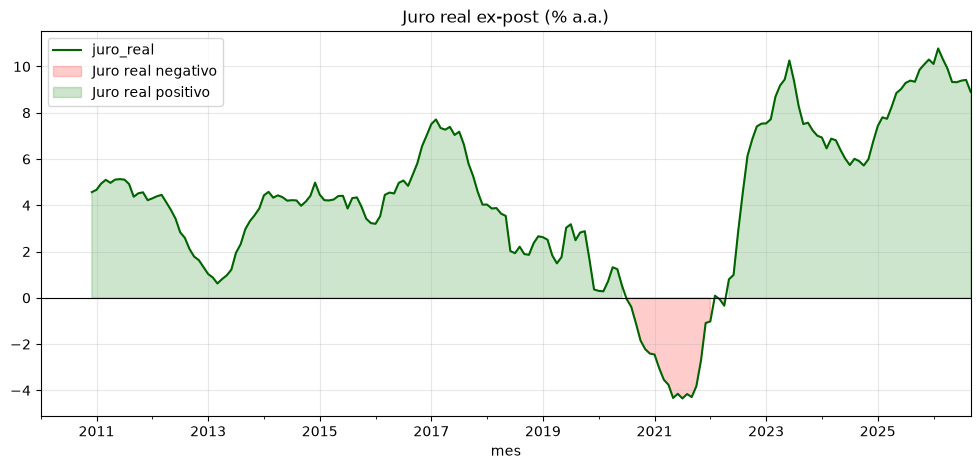

Média do juro real: 4.12
Meses com juro real negativo: 21
Máximo: 2026-02-01 10.78


In [4]:
fig, ax = plt.subplots()
df["juro_real"].plot(ax=ax, color="darkgreen")
ax.axhline(0, color="black", lw=0.8)
ax.fill_between(df.index, df["juro_real"], 0, where=df["juro_real"] < 0,
                color="red", alpha=0.2, label="Juro real negativo")
ax.fill_between(df.index, df["juro_real"], 0, where=df["juro_real"] >= 0,
                color="green", alpha=0.2, label="Juro real positivo")
ax.set_title("Juro real ex-post (% a.a.)")
ax.legend()
plt.savefig("../imagens/02_juro_real.png", dpi=150, bbox_inches="tight")
plt.show()

print("Média do juro real:", round(df["juro_real"].mean(), 2))
print("Meses com juro real negativo:", int((df["juro_real"] < 0).sum()))
print("Máximo:", df["juro_real"].idxmax().date(), round(df["juro_real"].max(), 2))

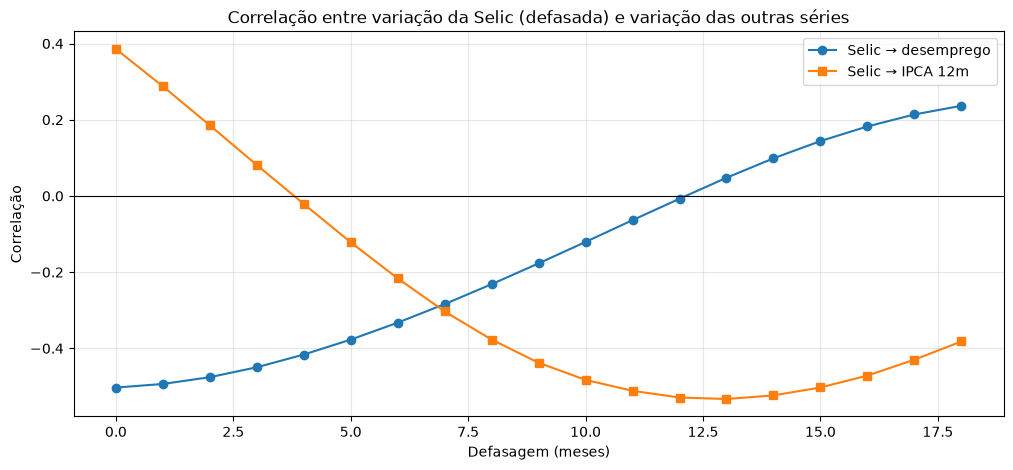

Maior correlação com desemprego: 0 meses -> -0.5
Maior correlação com IPCA: 13 meses -> -0.53


In [5]:
def corr_defasada(x, y, max_lag=18):
    """Correlação entre x defasado em 'lag' meses e y hoje."""
    return pd.Series({lag: x.shift(lag).corr(y) for lag in range(max_lag + 1)})

d_selic = df["selic_media"].diff(12)          # variação da Selic em 12 meses
d_desemp = df["desemprego"].diff(12)          # variação do desemprego em 12 meses
d_ipca = df["ipca_12m"].diff(12)

c_desemp = corr_defasada(d_selic, d_desemp)
c_ipca = corr_defasada(d_selic, d_ipca)

fig, ax = plt.subplots()
c_desemp.plot(ax=ax, marker="o", label="Selic → desemprego")
c_ipca.plot(ax=ax, marker="s", label="Selic → IPCA 12m")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Defasagem (meses)")
ax.set_ylabel("Correlação")
ax.set_title("Correlação entre variação da Selic (defasada) e variação das outras séries")
ax.legend()
plt.savefig("../imagens/03_correlacao_defasada.png", dpi=150, bbox_inches="tight")
plt.show()

print("Maior correlação com desemprego:", c_desemp.abs().idxmax(), "meses ->", round(c_desemp[c_desemp.abs().idxmax()], 2))
print("Maior correlação com IPCA:", c_ipca.abs().idxmax(), "meses ->", round(c_ipca[c_ipca.abs().idxmax()], 2))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4566      0.039     11.805      0.000       0.381       0.532
dolar_lag0    -0.0149      0.009     -1.636      0.102      -0.033       0.003
dolar_lag1    -0.0027      0.008     -0.365      0.715      -0.018       0.012
dolar_lag2    -0.0041      0.010     -0.423      0.672      -0.023       0.015
dolar_lag3     0.0020      0.009      0.231      0.817      -0.015       0.019
dolar_lag4     0.0221      0.008      2.881      0.004       0.007       0.037
dolar_lag5     0.0070      0.009      0.817      0.414      -0.010       0.024
dolar_lag6     0.0112      0.006      1.759      0.079      -0.001       0.024

Repasse acumulado em 6 meses: 0.021 p.p. no IPCA para cada 1% de variação no dólar


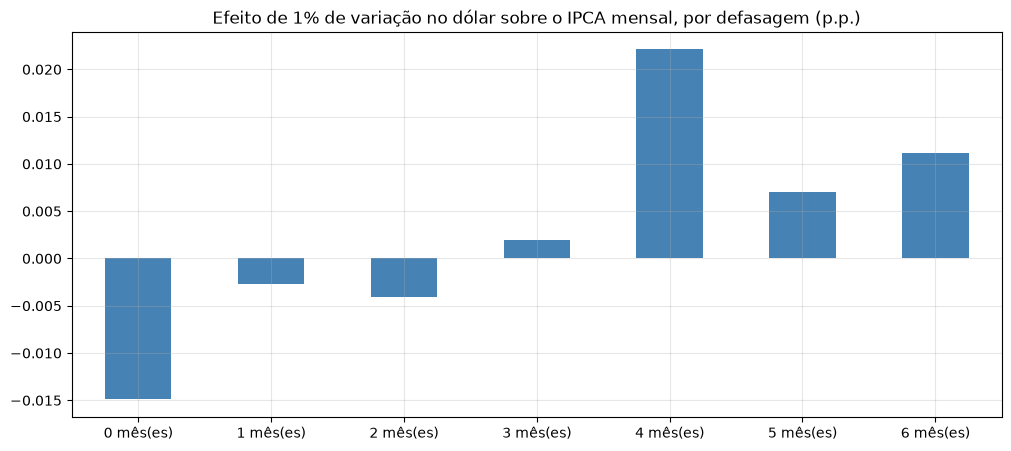

In [6]:
lags = range(0, 7)
X = pd.concat({f"dolar_lag{l}": df["dolar_var_pct"].shift(l) for l in lags}, axis=1)
dados = pd.concat([df["ipca_mensal"], X], axis=1).dropna()

modelo = sm.OLS(
    dados["ipca_mensal"],
    sm.add_constant(dados.drop(columns="ipca_mensal")),
).fit(cov_type="HAC", cov_kwds={"maxlags": 6})   # erros robustos a autocorrelação

print(modelo.summary().tables[1])

coefs = modelo.params.drop("const")
repasse_total = coefs.sum()
print(f"\nRepasse acumulado em 6 meses: {repasse_total:.3f} p.p. no IPCA para cada 1% de variação no dólar")

fig, ax = plt.subplots()
coefs.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Efeito de 1% de variação no dólar sobre o IPCA mensal, por defasagem (p.p.)")
ax.set_xticklabels([f"{l} mês(es)" for l in lags], rotation=0)
plt.savefig("../imagens/04_repasse_cambial.png", dpi=150, bbox_inches="tight")
plt.show()

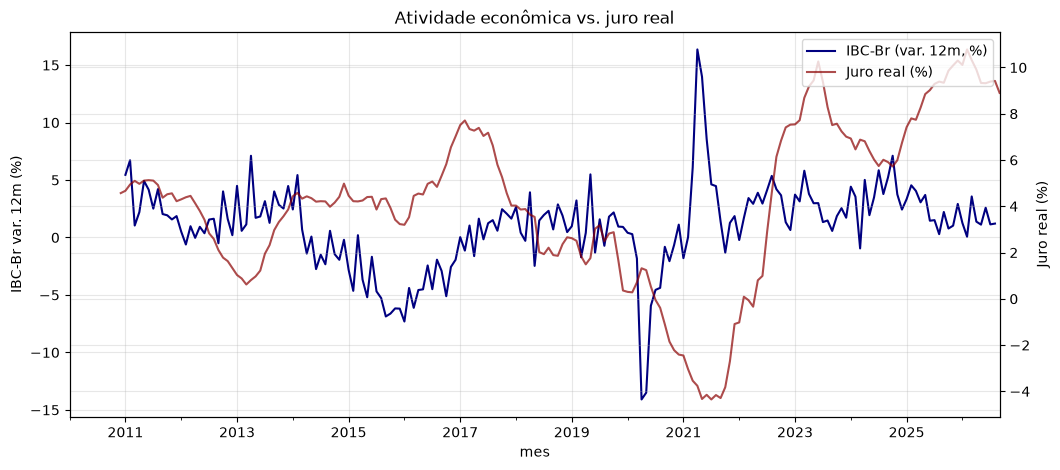

In [7]:
fig, ax1 = plt.subplots()
df["ibc_br_var_12m"].plot(ax=ax1, color="navy", label="IBC-Br (var. 12m, %)")
ax1.set_ylabel("IBC-Br var. 12m (%)")
ax2 = ax1.twinx()
df["juro_real"].plot(ax=ax2, color="darkred", alpha=0.7, label="Juro real (%)")
ax2.set_ylabel("Juro real (%)")
ax1.set_title("Atividade econômica vs. juro real")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.savefig("../imagens/05_atividade_juro_real.png", dpi=150, bbox_inches="tight")
plt.show()

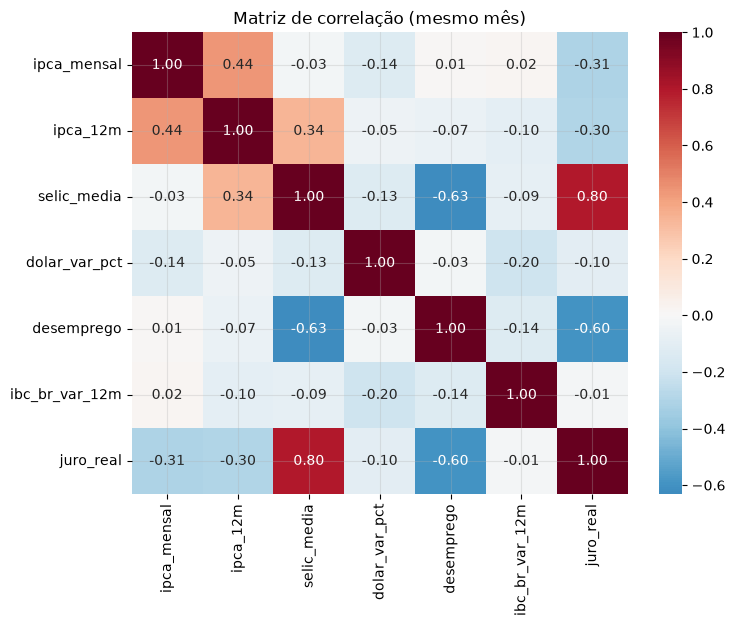

In [8]:
variaveis = df[["ipca_mensal", "ipca_12m", "selic_media", "dolar_var_pct",
                "desemprego", "ibc_br_var_12m", "juro_real"]].dropna()

import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(variaveis.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Matriz de correlação (mesmo mês)")
plt.savefig("../imagens/06_matriz_correlacao.png", dpi=150, bbox_inches="tight")
plt.show()